In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
%matplotlib inline

In [16]:
# To fix CP949 error
from sklearn import set_config
set_config(display="text")

In [17]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv',encoding='utf-8')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [18]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [19]:
# Data Preparation
# categorical -> NA
# numerical -> 0.0
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [20]:
categorical = [i for i in df.columns if df[i].dtype == "str"]
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [21]:
numerical = [i for i in df.columns if i not in categorical and i != "converted"]
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [22]:
df[categorical] = df[categorical].fillna("NA")
for c in categorical:
    df[c] = df[c].str.lower().str.replace(" ","_")

df[numerical] = df[numerical].fillna(0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [23]:
# Data Spliting
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

## Q1. ROC AUC feature importance

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [25]:
for num in numerical:
    y_pred = df_train[num].values
    y_val = df_train["converted"].values
    score = roc_auc_score(y_val,y_pred)
    print(num,": ",score)    

annual_income :  0.6081977776250831
number_of_courses_viewed :  0.7229894623989618
interaction_count :  0.7649203047563227
lead_score :  0.7882254810906102


lead_score has the highest AUC score

## Q2. Training the model

In [35]:
#OHE
from sklearn.feature_extraction import DictVectorizer

In [36]:
# To initialize dv (with full data)
dicts = df[categorical+numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
dv.fit_transform(dicts)

array([[8.8160e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       [7.2688e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        3.0000e+00],
       [4.4697e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       ...,
       [5.3636e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        4.0000e+00],
       [6.9430e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        4.0000e+00],
       [8.1355e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        6.0000e+00]], shape=(5000, 28))

In [37]:
# for training set
dicts = df_train[categorical+numerical].to_dict(orient='records')
X_train = dv.fit_transform(dicts)
y_train = df_train.converted.values

In [38]:
# for validation set
dicts = df_val[categorical+numerical].to_dict(orient='records')
X_val = dv.fit_transform(dicts)
y_val = df_val.converted.values

In [39]:
# for test set
dicts = df_test[categorical+numerical].to_dict(orient='records')
X_test = dv.fit_transform(dicts)
y_test = df_test.converted.values

In [40]:
# Training
from sklearn.linear_model import LogisticRegression

In [41]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [45]:
y_pred = model.predict_proba(X_val)[:,1]
score = roc_auc_score(y_val,y_pred)
score

0.7318222288173319

## Q3. Precision and Recall

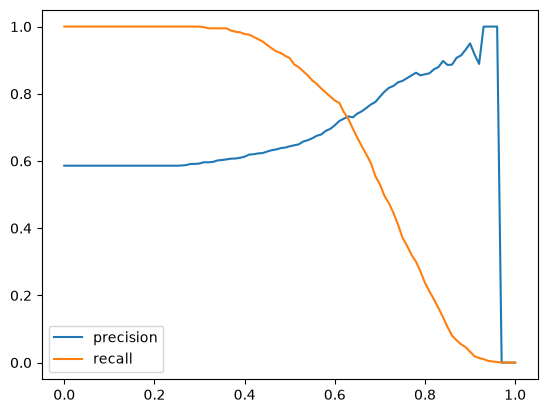

In [78]:
thresholds = np.linspace(0,1,101)
precision= []
recall = []

min_i = 0
abs_diff = 1

for i in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= i)
    predict_negative = (y_pred < i)

    TP = (actual_positive & predict_positive).sum()
    FP = (actual_negative & predict_positive).sum()

    TN = (actual_negative & predict_negative).sum()
    FN = (actual_positive & predict_negative).sum()

    if (TP+FP) == 0:
        P = 0
    else:
        P = TP / (TP+FP)
    
    if (TP+FN) == 0:
        R = 0
    else:
        R = TP / (TP+FN)

    if (P != 0) and (R != 0):
        if abs(P-R) < abs_diff:
            min_i = i
            abs_diff = abs(P-R)

    precision.append(P)
    recall.append(R)
    
plt.plot(thresholds, precision, label="precision")
plt.plot(thresholds, recall, label="recall")
plt.legend()

In [79]:
print(min_i)

0.63


# Q4. F1 Score

In [93]:
thresholds = np.linspace(0,1,101)
F_1 = []
idx = []

for i in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= i)
    predict_negative = (y_pred < i)

    TP = (actual_positive & predict_positive).sum()
    FP = (actual_negative & predict_positive).sum()

    TN = (actual_negative & predict_negative).sum()
    FN = (actual_positive & predict_negative).sum()

    if (TP+FP) == 0:
        P = 0
    else:
        P = TP / (TP+FP)
    
    if (TP+FN) == 0:
        R = 0
    else:
        R = TP / (TP+FN)

    if (P != 0) and (R != 0):
        F = 2*(P*R)/(P+R)

    F_1.append(F)
    idx.append(i)

F1_score = pd.DataFrame({"F1":F_1},index=idx)
F1_score[F1_score["F1"] == F1_score["F1"].max()]

,F1
0.41,0.757616


## Q5. 5-Fold CV

In [101]:
from sklearn.model_selection import KFold
df_full_train = df_full_train.reset_index()

In [102]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical+numerical].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train,y_train)

    return dv, model

In [103]:
def predict(df, dv, model):
    dicts = df[categorical+numerical].to_dict(orient="records")

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [120]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values 
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    score = roc_auc_score(y_val,y_pred) 
    scores.append(score)
    
round(np.std(scores),3).item()

0.007

## Q6. Hyperparameter Tuning

In [125]:
C = [0.000001, 0.001, 1]

for c in C:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values 
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, C=c)
        y_pred = predict(df_val, dv, model)
    
        score = roc_auc_score(y_val,y_pred) 
        scores.append(score)

    ROCAUC = round(np.mean(scores).item(),3)
    print(c,": ",ROCAUC)


1e-06 :  0.617
0.001 :  0.749
1 :  0.732
